# 05 · Entropy comparison

Two full training runs on COCO train2017 (118k images, 256 px, batch 32,
10k steps, Kaggle T4), identical except for the entropy weight: 0.01 and 0.05.

During training, both reached zero unused tones on validation images. The
lower entropy also reached a lower reconstruction error. This notebook checks
what the numbers do not show: how memberships and recoloring actually look,
to pick the configuration that becomes the reference model.

All evaluation images come from COCO val2017 and were never used in training.

In [1]:
import os
from pathlib import Path

from dotenv import load_dotenv

load_dotenv()

import matplotlib.pyplot as plt
import numpy as np
import torch
from PIL import Image
from tensorboard.backend.event_processing.event_accumulator import EventAccumulator
from torchvision import transforms

from aquarelab.data import find_images, make_loader, prepare_batch
from aquarelab.losses import palette_from_weights, reconstruct
from aquarelab.metrics import tone_ownership
from aquarelab.model import PaletteNet
from aquarelab.recolor import assign_by_luminance, hex_to_lab, lab_to_rgb, recolor

os.makedirs("figures", exist_ok=True)
device = "cuda" if torch.cuda.is_available() else "cpu"
print(f"Using device: {device}")

Using device: cuda


In [2]:
CHECKPOINTS = Path("../checkpoints")
RUNS = Path("../runs")
VAL_ROOT = Path("../datasets/coco/val2017")
TEST_IMAGE = Path("data/florest.jpg")

CONFIGS = {"entropy 0.01": "entropy_001", "entropy 0.05": "entropy_005"}

EVAL_IMAGES = 500
IMAGE_SIZE = 256
BATCH_SIZE = 16
DEAD_THRESHOLD = 0.01  # a tone owning less than 1% of the pixels is considered unused
SHOWCASE = [0, 1, 2, 3, 4]  # val images shown side by side; change to explore others

LAB_SCALE = torch.tensor([1 / 100, 1 / 128, 1 / 128]).view(1, 3, 1, 1)

new_palette = hex_to_lab([
    "#264653", "#2a9d8f", "#8ab17d", "#e9c46a",
    "#f4a261", "#e76f51", "#b56576", "#6d597a",
])

In [3]:
def latest_run(prefix: str, root: Path) -> Path:
    """Most recent run folder whose name starts with prefix."""
    matches = sorted(root.glob(f"{prefix}_*"))
    if not matches:
        raise FileNotFoundError(f"No run starting with '{prefix}' in {root}")
    return matches[-1]


def load_model(run_dir: Path) -> tuple[PaletteNet, int]:
    """Load the final checkpoint of a run. Pretrained weights are not needed, they are in the checkpoint."""
    path = sorted(run_dir.glob("step_*.pt"))[-1]
    state = torch.load(path, map_location="cpu", weights_only=True)
    model_cfg = state["config"]["model"]
    model = PaletteNet(
        num_tones=model_cfg["num_tones"], backbone=model_cfg["backbone"], pretrained=False
    )
    model.load_state_dict(state["model"])
    return model.to(device).eval(), state["step"]


@torch.no_grad()
def run_model(model, rgb):
    net_input, lab = prepare_batch(rgb.to(device))
    weights = model(net_input)
    palette = palette_from_weights(lab, weights)
    recon = reconstruct(weights, palette)
    return lab, weights, palette, recon


@torch.no_grad()
def evaluate(model, loader) -> dict:
    """Per-image metrics over the whole evaluation set."""
    l1, used, decision, owned_all = [], [], [], []
    scale = LAB_SCALE.to(device)
    for rgb in loader:
        lab, weights, _, recon = run_model(model, rgb)
        owned = tone_ownership(weights)
        l1.append(((lab - recon) * scale).abs().mean(dim=(1, 2, 3)).cpu())
        used.append((owned >= DEAD_THRESHOLD).sum(dim=1).cpu())
        decision.append(weights.max(dim=1).values.mean(dim=(1, 2)).cpu())
        owned_all.append(owned.cpu())
    owned = torch.cat(owned_all)
    return {
        "l1": torch.cat(l1).numpy(),
        "tones_used": torch.cat(used).numpy(),
        "decision": torch.cat(decision).numpy(),
        "unused_tones": int((owned.mean(dim=0) < DEAD_THRESHOLD).sum()),
    }


def load_images(paths: list[Path]) -> torch.Tensor:
    transform = transforms.Compose([
        transforms.Resize(IMAGE_SIZE, antialias=True),
        transforms.CenterCrop(IMAGE_SIZE),
        transforms.ToTensor(),
    ])
    return torch.stack([transform(Image.open(p).convert("RGB")) for p in paths])


def describe(model, rgb: torch.Tensor) -> list[dict]:
    """Reconstruction, tone maps and recoloring for a few images, as numpy arrays."""
    lab, weights, palette, recon = run_model(model, rgb)
    owned = tone_ownership(weights).cpu().numpy()
    results = []
    for i in range(len(rgb)):
        image = rgb[i].permute(1, 2, 0).numpy()
        weights_np = weights[i].permute(1, 2, 0).cpu().numpy()
        palette_np = palette[i].cpu().numpy()
        matched = assign_by_luminance(
            palette_np, new_palette, usage=owned[i], min_usage=DEAD_THRESHOLD
        )
        results.append({
            "image": image,
            "weights": weights_np,
            "palette": palette_np,
            "owned": owned[i],
            "recon": lab_to_rgb(recon[i].permute(1, 2, 0).cpu().numpy()),
            "recolored": recolor(image, weights_np, palette_np, matched),
        })
    return results


def read_scalars(run_dir: Path, tag: str) -> tuple[list[int], list[float]]:
    accumulator = EventAccumulator(str(run_dir), size_guidance={"scalars": 0})
    accumulator.Reload()
    events = accumulator.Scalars(tag)
    return [e.step for e in events], [e.value for e in events]

In [4]:
models = {}
for label, prefix in CONFIGS.items():
    run_dir = latest_run(prefix, CHECKPOINTS)
    model, step = load_model(run_dir)
    models[label] = model
    print(f"{label:<14} | {run_dir.name} | step {step}")

entropy 0.01   | entropy_001_20261122-175911 | step 10000
entropy 0.05   | entropy_005_20261122-190151 | step 10000


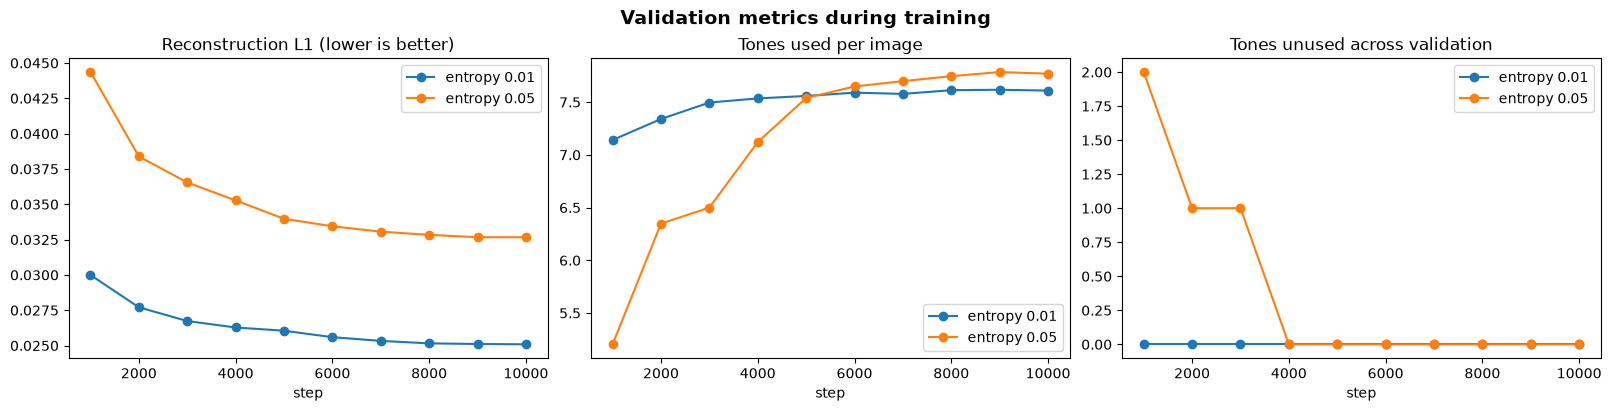

In [5]:
tags = {
    "val/recon_l1": "Reconstruction L1 (lower is better)",
    "val/tones_per_image": "Tones used per image",
    "val/unused_tones": "Tones unused across validation",
}

fig, axes = plt.subplots(1, 3, figsize=(16, 4), layout="constrained")
for ax, (tag, title) in zip(axes, tags.items()):
    for label, prefix in CONFIGS.items():
        steps, values = read_scalars(latest_run(prefix, RUNS), tag)
        ax.plot(steps, values, marker="o", label=label)
    ax.set_title(title)
    ax.set_xlabel("step")
    ax.legend()

fig.suptitle("Validation metrics during training", fontsize=14, fontweight="bold")
plt.savefig("figures/05_training_curves.png", dpi=120, bbox_inches="tight")
plt.show()

In [6]:
loader = make_loader(
    VAL_ROOT, batch_size=BATCH_SIZE, image_size=IMAGE_SIZE,
    train=False, num_workers=0, max_images=EVAL_IMAGES,
)
results = {label: evaluate(model, loader) for label, model in models.items()}

print(f"Evaluated on {len(loader.dataset)} unseen images\n")
print(f"{'Config':<14} | {'Recon L1':>9} | {'Tones/image':>11} | {'Decision':>8} | {'Unused':>6}")
print("-" * 60)
for label, r in results.items():
    print(
        f"{label:<14} | {r['l1'].mean():>9.4f} | {r['tones_used'].mean():>11.1f} "
        f"| {r['decision'].mean():>8.3f} | {r['unused_tones']:>6d}"
    )

a, b = results["entropy 0.01"]["l1"], results["entropy 0.05"]["l1"]
print(f"\nImages where entropy 0.01 reconstructs better: {(a < b).mean():.0%}")

Evaluated on 500 unseen images

Config         |  Recon L1 | Tones/image | Decision | Unused
------------------------------------------------------------
entropy 0.01   |    0.0260 |         7.6 |    0.848 |      0
entropy 0.05   |    0.0334 |         7.8 |    0.988 |      0

Images where entropy 0.01 reconstructs better: 99%


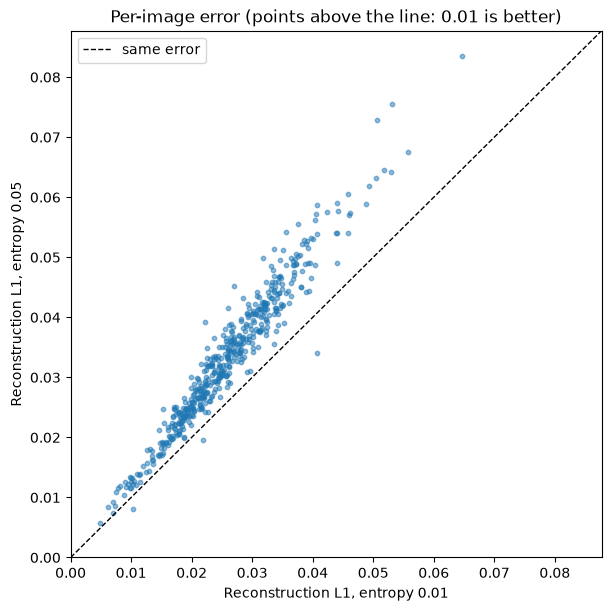

In [7]:
fig, ax = plt.subplots(figsize=(6, 6), layout="constrained")
ax.scatter(a, b, s=10, alpha=0.5)
limit = max(a.max(), b.max()) * 1.05
ax.plot([0, limit], [0, limit], "k--", linewidth=1, label="same error")
ax.set_xlim(0, limit)
ax.set_ylim(0, limit)
ax.set_xlabel("Reconstruction L1, entropy 0.01")
ax.set_ylabel("Reconstruction L1, entropy 0.05")
ax.set_title("Per-image error (points above the line: 0.01 is better)")
ax.legend()
plt.savefig("figures/05_l1_per_image.png", dpi=120, bbox_inches="tight")
plt.show()

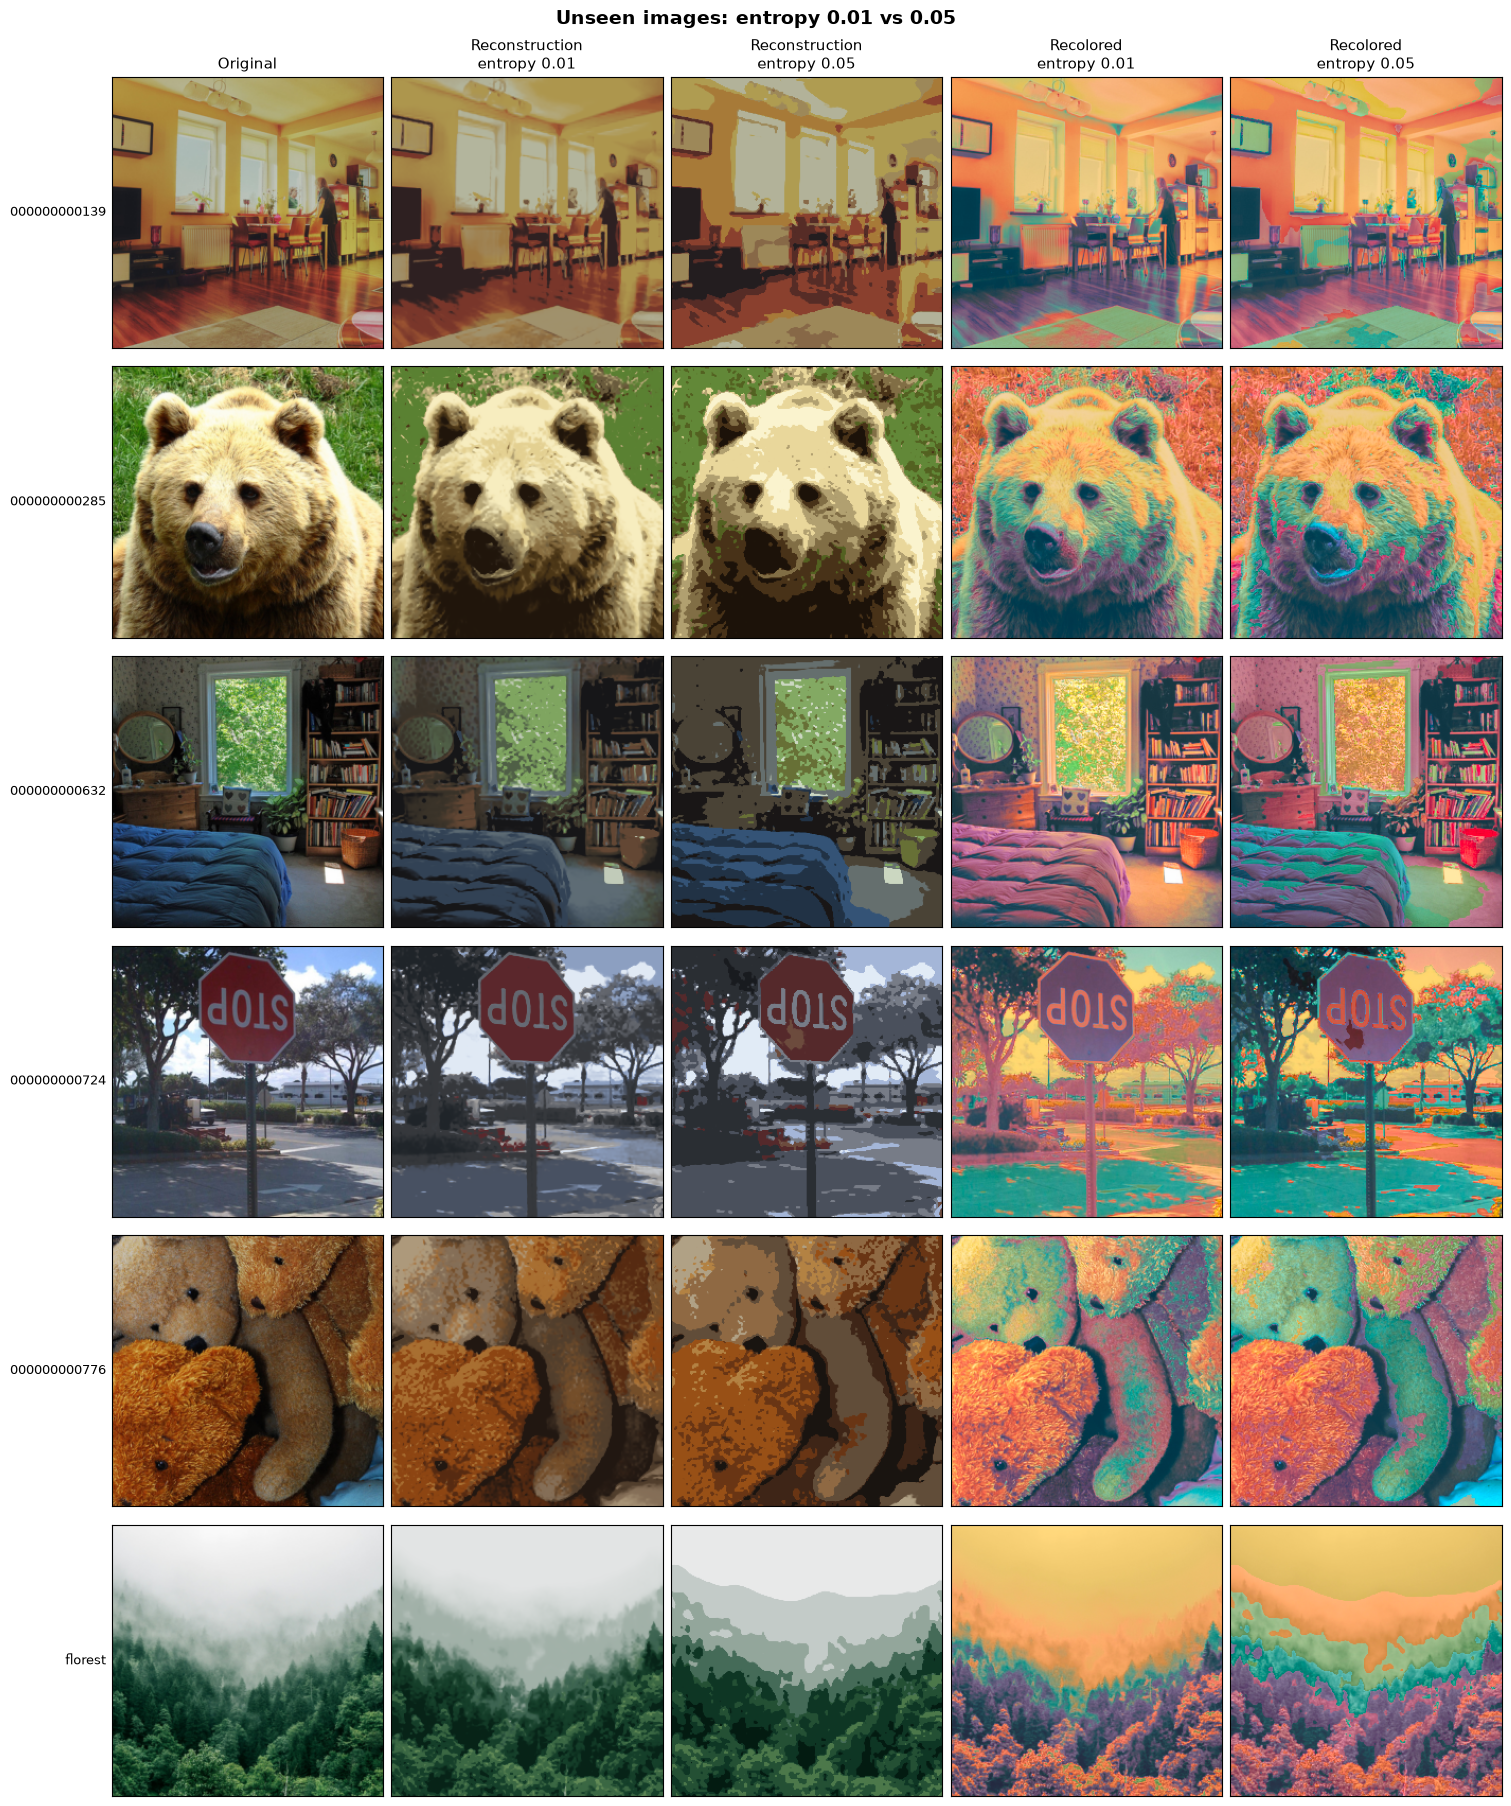

In [8]:
eval_paths = find_images(VAL_ROOT, max_images=EVAL_IMAGES)
showcase_paths = [eval_paths[i] for i in SHOWCASE] + [TEST_IMAGE]
showcase_rgb = load_images(showcase_paths)
described = {label: describe(model, showcase_rgb) for label, model in models.items()}

labels = list(CONFIGS)
columns = ["Original"] + [f"Reconstruction\n{l}" for l in labels] + [f"Recolored\n{l}" for l in labels]

fig, axes = plt.subplots(
    len(showcase_paths), len(columns),
    figsize=(3 * len(columns), 3 * len(showcase_paths)), layout="constrained",
)
for row, i in zip(axes, range(len(showcase_paths))):
    images = (
        [described[labels[0]][i]["image"]]
        + [described[l][i]["recon"] for l in labels]
        + [described[l][i]["recolored"] for l in labels]
    )
    for ax, image in zip(row, images):
        ax.imshow(image)
        ax.set_xticks([])
        ax.set_yticks([])
    row[0].set_ylabel(showcase_paths[i].stem, rotation=0, ha="right", va="center", fontsize=9)

for ax, title in zip(axes[0], columns):
    ax.set_title(title, fontsize=11)

fig.suptitle("Unseen images: entropy 0.01 vs 0.05", fontsize=14, fontweight="bold")
plt.savefig("figures/05_comparison.png", dpi=120, bbox_inches="tight")
plt.show()

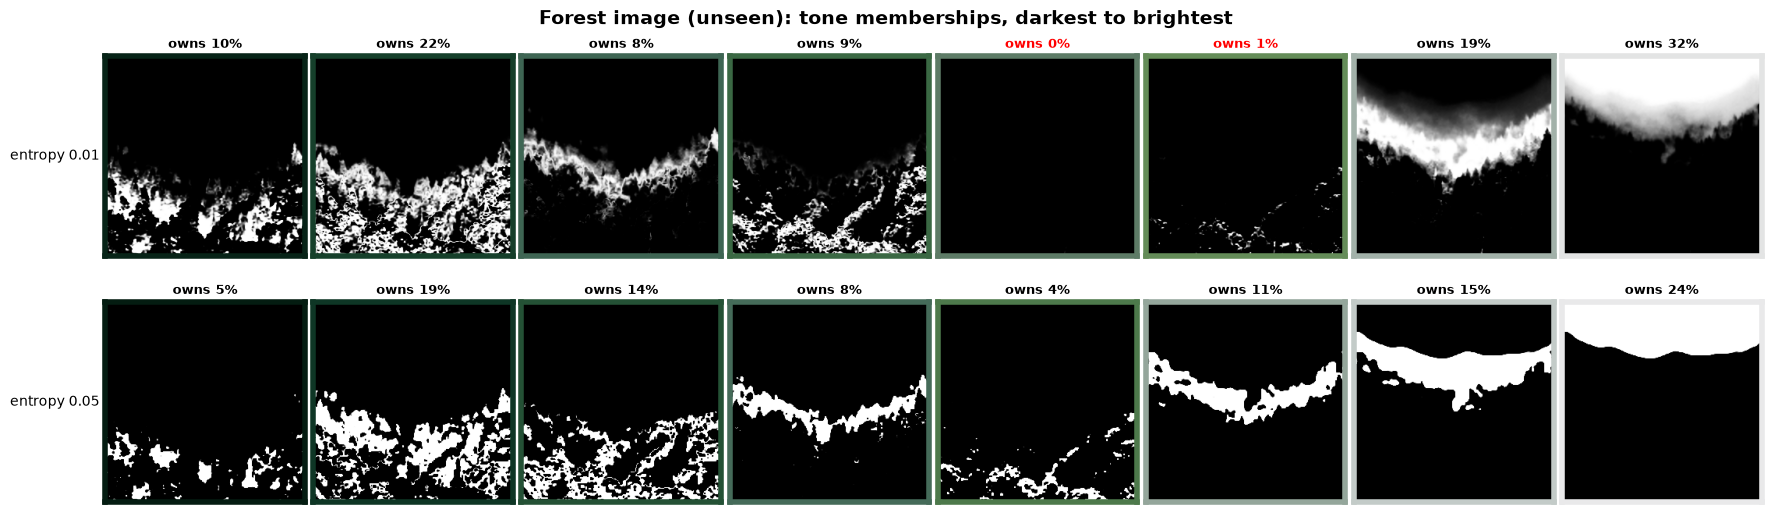

In [9]:
num_tones = described[labels[0]][-1]["weights"].shape[-1]
fig, axes = plt.subplots(
    len(labels), num_tones, figsize=(2.2 * num_tones, 2.6 * len(labels)), layout="constrained"
)
for row, label in zip(axes, labels):
    forest = described[label][-1]
    order = np.argsort(forest["palette"][:, 0])  # darkest to brightest
    for ax, tone in zip(row, order):
        ax.imshow(forest["weights"][..., tone], cmap="gray", vmin=0, vmax=1)
        swatch = lab_to_rgb(forest["palette"][tone][None, None, :])[0, 0]
        unused = forest["owned"][tone] < DEAD_THRESHOLD
        ax.set_title(
            f"owns {forest['owned'][tone]:.0%}",
            color="red" if unused else "black", fontweight="bold", fontsize=9,
        )
        ax.set_xticks([])
        ax.set_yticks([])
        for spine in ax.spines.values():
            spine.set_edgecolor(swatch)
            spine.set_linewidth(4)
    row[0].set_ylabel(label, rotation=0, ha="right", va="center", fontsize=10)

fig.suptitle(
    "Forest image (unseen): tone memberships, darkest to brightest",
    fontsize=14, fontweight="bold",
)
plt.savefig("figures/05_forest_tone_maps.png", dpi=120, bbox_inches="tight")
plt.show()

## Conclusions

**Entropy 0.01 becomes the reference model.**

**The training metrics hold image by image.** Entropy 0.01 reconstructs better
on 99% of 500 unseen images (L1 0.0260 vs 0.0334). The gap is consistent and
grows on harder images. Both configurations end with zero unused tones.

**Entropy 0.05 makes memberships almost hard.** The winning tone holds 98.8% of
each pixel's weight on average, against 84.8% with 0.01. Reconstructions with
0.05 look posterized: flat areas with sharp contours.

**Soft memberships are what makes recoloring look natural.** With 0.05, every
boundary between tones becomes a hard color edge: wavy stripes across the fog,
a patch on the stop sign, patches on the bed and floor. With 0.01, the fog goes
from yellow to orange to purple with no stripes at all. This is the artifact
seen since notebook 01, and it is gone. The forest tone maps show why: with
0.01 the fog is covered by two tones that overlap gradually, and the Lab shift
turns a gradual overlap into a gradual color change. With 0.05 the maps are
binary masks.

**Stronger entropy was the wrong intuition.** It was tested to stop faint ghost
tones, but training on many images with a batch-level floor already solved that.
Decisive memberships hurt recoloring.

**Fine textures are still a limitation.** On fur, grass and plush, both
configurations split tones by light and dark within the texture, and the
recolored result looks speckled with two colors. Large regions (sky, fog,
signs, walls) follow objects; fine textures still follow luminance.

**Per-image tone usage varies, as intended.** On the forest image, two tones own
0-1% of the pixels. With the batch-level floor, simple images may use fewer
tones as long as every tone is used somewhere in the dataset.